# Person 1: Google Trends, Prepared Dataset, Baselines and Simpler Models (E1)

**Project:** Fashion Trend Forecasting (ML group project) &nbsp;|&nbsp; **Experiment:** E1, Google Trends forecasting &nbsp;|&nbsp; **Notebook for:** Person 1

This notebook continues from the Google Trends pull and EDA notebook. It does the following, in this order:

| Step | What happens | Section |
|---|---|---|
| 1 | Finish cleaning: incomplete weeks, spike weeks, keywords with little history | 3 |
| 2 | Prepare inputs: previous weeks, recent averages, growth, volatility, seasonality, market index | 4 to 5 |
| 3 | Prepare the time splits: training, validation (3 yearly folds) and test | 6 |
| 4 | Three baselines: latest value, four-week average, same week last year | 7 |
| 5 | Simpler models: exponential smoothing (ETS), Ridge and Lasso | 8 to 10 |
| 6 | Tune Ridge and Lasso on the validation folds | 9 |
| 7 | Save predictions, scores, coefficients and example forecast graphs in the shared format | 11 to 14 |

**Inputs** (from the EDA notebook): `raw_pulls/trends_weekly_raw.csv` (stitched weekly table) and `google_trends_keywords.xlsx` (keyword categories). The folder `raw_pulls/` is also used to recompute which keywords have a weak stitch.

**Outputs** (all in `results/google_trends/`, the shared format agreed with the team):

| File | For whom | Content |
|---|---|---|
| `predictions.csv` | everyone | `date, item, horizon, actual, predicted, model, period, last4_avg` for all baselines and models; `date` is the forecast-origin week |
| `scores.csv` | everyone | MAE, RMSE, MASE and growth-direction accuracy per model, period, horizon and scope |
| `prepared_dataset.csv.gz` | **Person 2** | the shared prepared dataset (one row per origin week, keyword and horizon) |
| `coefficients.csv`, `coefficients_summary.csv` | **Person 2** | Ridge and Lasso coefficients |
| `tuning_results.csv`, `keyword_info.csv`, `spike_weeks.csv`, `trends_weekly_prepared.csv`, `splits.json`, `feature_list.json` | everyone | tuning results, keyword flags, spike flags, cleaned weekly table and the split definitions |
| `figures/` | report | example forecast graphs, score comparison, tuning curves, coefficients |

**How to run:** open this notebook from the project root, set the parameters in section 1 (the defaults match the project plan) and run all cells. The first full run takes several minutes (ETS is the slowest part). Set `QUICK_RUN = True` for a fast check on a subset of keywords.

## 1. Setup and parameters

All choices below come from the proposal (Model Selection and Experimental Design chapter) or from the EDA findings. The comment next to each setting says where it comes from.

In [47]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [48]:
# ---------------------------------------------------------------- paths and run options
DATA_DIR = "."                          # folder with the EDA outputs
RAW_FILE = "raw_pulls/trends_weekly_raw.csv"  # stitched weekly table from the EDA notebook
KEYWORDS_FILE = "google_trends_keywords.xlsx"   # sheet "Keywords" with columns Keyword and Category
RAW_PULLS_DIR = "raw_pulls"             # optional: used to recompute the weak-stitch keywords
OUT_DIR = "results/google_trends"       # shared results folder (agreed format)

QUICK_RUN = False                       # True = small subset of keywords, for a fast check
RUN_ETS = True                          # exponential smoothing is the slowest part
N_JOBS = -1                             # CPU cores for ETS (-1 = all)

# ---------------------------------------------------------------- forecasting task (proposal)
HORIZONS = [4, 8]                       # weeks ahead
REFIT_EVERY = 4                         # retrain every 4 weeks in the test period
TEST_START = "2025-01-01"               # final test: January 2025 to the end of the data
FOLDS = [                               # three yearly backtests used to choose the settings
    dict(name="val_2022", train_end="2021-12-31", val_start="2022-01-01", val_end="2022-12-31"),
    dict(name="val_2023", train_end="2022-12-31", val_start="2023-01-01", val_end="2023-12-31"),
    dict(name="val_2024", train_end="2023-12-31", val_start="2024-01-01", val_end="2024-12-31"),
]

# ---------------------------------------------------------------- cleaning decisions (from the EDA)
RECENT_WEEKS = 261                      # length of the recent pull window (weeks)
WEAK_STITCH_MIN_VOLUME = 3              # overlap mean below this = unreliable stitch factor
WEAK_STITCH_FALLBACK = ["barrel jeans", "balloon skirt", "oversized sunglasses",
                        "floral print", "quiet luxury", "balletcore"]   # used if raw_pulls/ is not available
ZERO_CUTOFF = 0.30                      # share of zero weeks that marks a low-volume keyword
RECENT_ZERO_WEEKS = 104                 # the zero share is now measured over the last 2 years only
SPIKE_MULTIPLE = 2                      # a keyword "spikes" when above 2x its normal level
SPIKE_SHARE = 0.25                      # a week is a spike week when more than 25% of keywords spike (proposal: about 0.25)

# ---------------------------------------------------------------- features and samples
LAGS = [0, 1, 2, 4, 8, 12, 26]          # weeks back (0 = the forecast week itself)
MIN_HISTORY = 52                        # at least one year of valid history before an origin week
MIN_BASE = 1.0                          # the 4-week average must be at least 1 (avoids ratios of tiny numbers)
FEATURE_CLIP = 5                        # ratio features are clipped to [0, 5]
TARGET_CLIP = 5                         # training target (value relative to the 4-week average) clipped at 5

# ---------------------------------------------------------------- models
RIDGE_ALPHAS = [0.01, 0.1, 1, 10, 100, 1000, 10000]
LASSO_ALPHAS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
ETS_SPEC = dict(error="add", trend="add", damped_trend=True)   # additive error, damped additive trend, no seasonality

OUT_DIR = Path(OUT_DIR)
DATA_DIR = Path(DATA_DIR)
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

def replace_existing(path):
    """Remove an old result before writing the replacement."""
    path = Path(path)
    path.unlink(missing_ok=True)
    return path

np.random.seed(42)
print("Results will be saved in:", OUT_DIR.resolve())

Results will be saved in: /Users/samichirungta/Desktop/fashion_trends/results/google_trends


## 2. Load the data

The stitched weekly table from the EDA notebook has one row per week (Sunday) and one column per keyword. Each keyword is on its own 0 to 100 scale, so it is only compared with its own past.

In [49]:
raw = pd.read_csv(DATA_DIR / RAW_FILE, index_col=0, parse_dates=True).sort_index()
full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="7D")
missing_weeks = full_index.difference(raw.index)
raw = raw.reindex(full_index)
raw.index.name = "date"

print(f"{raw.shape[0]} weeks x {raw.shape[1]} keywords, {raw.index.min().date()} to {raw.index.max().date()} "
      f"(weeks start on a {raw.index[0].day_name()})")
print("Weeks missing from the weekly index:", len(missing_weeks))
print("Missing values in the table:", int(raw.isna().sum().sum()))

kw_path = DATA_DIR / KEYWORDS_FILE
if kw_path.exists():
    kw_df = pd.read_excel(kw_path, sheet_name="Keywords")
    category = dict(zip(kw_df["Keyword"], kw_df["Category"]))
else:
    print(f"WARNING: {kw_path} not found, all keywords get the category 'Unknown'")
    category = {}
category = {k: category.get(k, "Unknown") for k in raw.columns}

if QUICK_RUN:
    examples = [k for k in ["cargo pants", "ballet flats", "blazer", "skinny jeans"] if k in raw.columns]
    keep = list(dict.fromkeys(list(raw.columns[::6]) + examples))
    raw = raw[keep]
    print(f"QUICK_RUN: using {raw.shape[1]} keywords")
raw.iloc[:3, :5]

489 weeks x 137 keywords, 2017-06-04 to 2026-10-11 (weeks start on a Sunday)
Weeks missing from the weekly index: 0
Missing values in the table: 228


,skinny jeans,wide leg jeans,baggy jeans,straight leg jeans,bootcut jeans
date,,,,,
2017-06-04,16.463153,0.990721,1.280813,1.959641,5.369217
2017-06-11,16.193265,0.880641,1.280813,1.650224,5.053381
2017-06-18,16.193265,0.880641,1.067344,1.856502,4.895463


## 3. Finish the cleaning

The EDA notebook found four things that need a decision. They follow the proposal and the open items from the EDA.

| Issue found in the EDA | Decision | Why |
|---|---|---|
| The incomplete last week | Already dropped when the data was pulled (`isPartial`). The last date is checked below | Google marks the latest week as partial |
| Six keywords have a **weak stitch** (too little volume in the 28-week overlap) | Use only the recent window for them (older values set to missing) | The rescaling factor of the older window is unreliable |
| `mob wife aesthetic` has no data in the older window | Its series starts when data first appears (missing before) | No data was returned for it |
| The zero-share cut-off (30% of **all** weeks) removed the emerging styles `balletcore`, `clean girl aesthetic`, `gorpcore` | Measure the zero share over the **last 104 weeks** instead, and keep emerging keywords with an `emerging` flag | Their early zeros show when the term appeared, not low volume today |
| Spring 2026 spike across unrelated keywords | **Flag** spike weeks (threshold 0.25, not 0.5), do not delete them. Results are reported for all weeks, for 2025 only and without spike weeks | A viral spike can be real; flagging keeps the data and lets us show the effect |

Nothing is deleted without being logged: the cleaning log is printed below and saved in `keyword_info.csv` and `spike_weeks.csv`.

In [50]:
# ---- 3.1 incomplete last week: the pull already drops Google's partial week; this is a second safety check
week_end = raw.index.max() + pd.Timedelta(days=6)
if week_end >= pd.Timestamp.today().normalize():
    print(f"The last week ({raw.index.max().date()}) is not finished yet, so it is dropped")
    raw = raw.iloc[:-1]
print("Last complete week in the data:", raw.index.max().date(), "| today:", pd.Timestamp.today().date())

# ---- 3.2 keywords with a weak stitch: recompute from raw_pulls/ if available, otherwise use the EDA list
def find_weak_stitch(columns, raw_dir):
    weak, checked = [], 0
    for kw in columns:
        stem = kw.replace(" ", "_")
        p_new, p_old = raw_dir / f"recent__{stem}.csv", raw_dir / f"old__{stem}.csv"
        if not (p_new.exists() and p_old.exists()):
            continue
        new = pd.read_csv(p_new, index_col=0, parse_dates=True)[kw]
        old = pd.read_csv(p_old, index_col=0, parse_dates=True)[kw]
        overlap = old.index.intersection(new.index)
        if len(overlap) == 0:
            continue
        checked += 1
        if old.loc[overlap].mean() < WEAK_STITCH_MIN_VOLUME or new.loc[overlap].mean() < WEAK_STITCH_MIN_VOLUME:
            weak.append(kw)
    return weak, checked

weak_stitch, n_checked = find_weak_stitch(raw.columns, DATA_DIR / RAW_PULLS_DIR)
if n_checked == 0:
    weak_stitch = [k for k in WEAK_STITCH_FALLBACK if k in raw.columns]
    print("raw_pulls/ not found: using the weak-stitch list from the EDA")
else:
    print(f"Weak stitch recomputed from raw_pulls/ ({n_checked} keywords checked)")
print("Weak-stitch keywords:", weak_stitch)

recent_start = raw.index[-RECENT_WEEKS]          # first week of the recent pull window
Y = raw.copy()
for kw in weak_stitch:
    Y.loc[Y.index < recent_start, kw] = np.nan   # use only the recent window for these keywords
print("Recent window starts:", recent_start.date())

# ---- 3.3 low-volume keywords (zero share over the last 104 weeks) and emerging keywords
valid_n = Y.notna().sum()
zero_full = (Y == 0).sum() / valid_n                         # over all valid weeks
zero_recent = (Y.iloc[-RECENT_ZERO_WEEKS:] == 0).mean()      # over the last 104 weeks
dropped = zero_recent[zero_recent > ZERO_CUTOFF].index.tolist()
emerging = [k for k in Y.columns if zero_full[k] > ZERO_CUTOFF and k not in dropped]
print("Dropped as low-volume (too many zeros in the last 104 weeks):", dropped)
print("Kept and flagged as emerging (many early zeros, fine recently):", emerging)

# ---- 3.4 keywords that start late (little history)
first_valid = Y.apply(lambda s: s.first_valid_index())
late_start = first_valid[first_valid > raw.index[0]]
print("Keywords whose series starts after the first week:")
print(late_start.dt.date.to_string() if len(late_start) else "none")

Y = Y.drop(columns=dropped)
print(f"\nCleaned table: {Y.shape[0]} weeks x {Y.shape[1]} keywords")

Last complete week in the data: 2026-10-11 | today: 2026-10-30
raw_pulls/ not found: using the weak-stitch list from the EDA
Weak-stitch keywords: ['barrel jeans', 'balloon skirt', 'oversized sunglasses', 'floral print', 'quiet luxury', 'balletcore']
Recent window starts: 2021-10-17
Dropped as low-volume (too many zeros in the last 104 weeks): []
Kept and flagged as emerging (many early zeros, fine recently): ['gorpcore', 'clean girl aesthetic', 'mob wife aesthetic']
Keywords whose series starts after the first week:
barrel jeans            2021-10-17
balloon skirt           2021-10-17
oversized sunglasses    2021-10-17
floral print            2021-10-17
quiet luxury            2021-10-17
balletcore              2021-10-17
mob wife aesthetic      2021-10-17

Cleaned table: 489 weeks x 137 keywords


10 spike weeks flagged (threshold 0.25):
['2026-02-08', '2026-02-15', '2026-03-29', '2026-04-05', '2026-04-12', '2026-04-19', '2026-04-26', '2026-05-03', '2026-05-10', '2026-05-17']


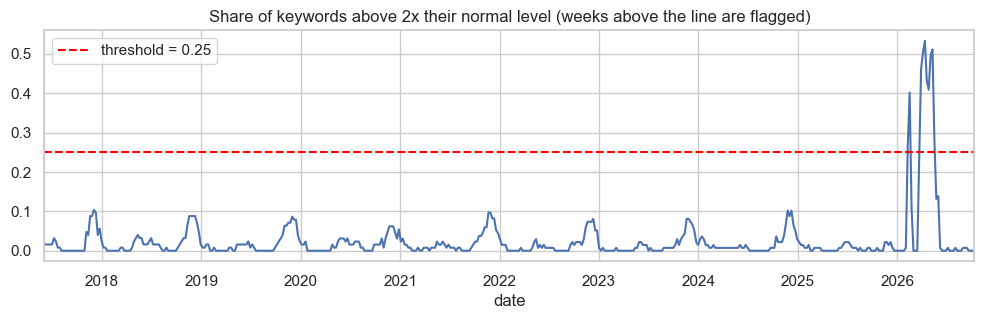

In [51]:
# ---- 3.5 spike weeks: share of keywords above 2x their own normal level (centred 52-week median)
# NOTE: the centred median looks ahead, so this flag is used only to REPORT results with and without
# spike weeks. It is never used as a model input.
normal_level = Y.rolling(52, center=True, min_periods=26).median()
rel_to_normal = (Y / normal_level).replace([np.inf, -np.inf], np.nan)
share_spiking = (rel_to_normal > SPIKE_MULTIPLE).sum(axis=1) / rel_to_normal.notna().sum(axis=1)
spike_flag = share_spiking > SPIKE_SHARE
spike_map = spike_flag.to_dict()

flagged = list(spike_flag[spike_flag].index.strftime("%Y-%m-%d"))
print(f"{len(flagged)} spike weeks flagged (threshold {SPIKE_SHARE}):")
print(flagged)

fig, ax = plt.subplots(figsize=(12, 3))
share_spiking.plot(ax=ax)
ax.axhline(SPIKE_SHARE, color="red", linestyle="--", label=f"threshold = {SPIKE_SHARE}")
ax.set_title("Share of keywords above 2x their normal level (weeks above the line are flagged)")
ax.legend()
plt.show()

In [52]:
# ---- 3.6 cleaning log and the files other people use
keyword_info = pd.DataFrame({
    "item": raw.columns,
    "category": [category[k] for k in raw.columns],
    "first_valid_date": [(Y[k] if k in Y else raw[k]).first_valid_index() for k in raw.columns],   # first usable week
    "zero_share_full": [(Y[k] == 0).sum() / Y[k].notna().sum() if k in Y else np.nan for k in raw.columns],
    "zero_share_last_104w": [zero_recent.get(k, np.nan) for k in raw.columns],
    "weak_stitch": [k in weak_stitch for k in raw.columns],
    "emerging": [k in emerging for k in raw.columns],
    "dropped_low_volume": [k in dropped for k in raw.columns],
})
keyword_info.to_csv(replace_existing(OUT_DIR / "keyword_info.csv"), index=False)
Y.to_csv(replace_existing(OUT_DIR / "trends_weekly_prepared.csv"))
pd.DataFrame({"share_spiking": share_spiking, "spike_week": spike_flag}).to_csv(replace_existing(OUT_DIR / "spike_weeks.csv"))

print("Cleaning log")
print(f"  keywords in the stitched table : {raw.shape[1]}")
print(f"  weak stitch (recent window only): {len(weak_stitch)}")
print(f"  dropped as low-volume           : {len(dropped)}")
print(f"  kept, flagged emerging          : {len(emerging)}")
print(f"  start late (little history)     : {len(late_start)}")
print(f"  spike weeks flagged (not removed): {int(spike_flag.sum())}")
print(f"  keywords used                   : {Y.shape[1]}")
keyword_info[keyword_info.weak_stitch | keyword_info.emerging | keyword_info.dropped_low_volume]

Cleaning log
  keywords in the stitched table : 137
  weak stitch (recent window only): 6
  dropped as low-volume           : 0
  kept, flagged emerging          : 3
  start late (little history)     : 7
  spike weeks flagged (not removed): 10
  keywords used                   : 137


,item,category,first_valid_date,zero_share_full,zero_share_last_104w,weak_stitch,emerging,dropped_low_volume
9,barrel jeans,Jeans and denim,2021-10-17,0.049808,0.000000,True,False,False
34,balloon skirt,Skirts and dresses,2021-10-17,0.000000,0.000000,True,False,False
96,oversized sunglasses,Accessories,2021-10-17,0.000000,0.000000,True,False,False
106,floral print,Patterns and materials,2021-10-17,0.000000,0.000000,True,False,False
121,quiet luxury,Aesthetics and styles,2021-10-17,0.026820,0.000000,True,False,False
124,balletcore,Aesthetics and styles,2021-10-17,0.118774,0.000000,True,False,False
125,gorpcore,Aesthetics and styles,2017-06-04,0.308793,0.000000,False,True,False
134,clean girl aesthetic,Aesthetics and styles,2017-06-04,0.498978,0.000000,False,True,False
135,mob wife aesthetic,Aesthetics and styles,2021-10-17,0.501916,0.134615,False,True,False


## 4. Prepare the inputs (features)

Every keyword is on its own 0 to 100 scale, so a value of 50 means something different for each style. To let **one global model** learn from all styles, every input and the target are divided by the style's own **4-week average** at the forecast week (the "base"). The forecast is converted back to the original scale before errors are measured.

Inputs, as described in the proposal (all use only the forecast week and earlier weeks):

| Group | Inputs |
|---|---|
| Previous weeks | value 0, 1, 2, 4, 8, 12 and 26 weeks back (`lag_k`) |
| Recent averages | 8, 12 and 26-week averages (`avg_k`) |
| Growth (momentum) | growth of the last 4, 8 and 12 weeks vs. the weeks before (`mom_k`), and whether growth speeds up (`accel_4`) |
| Volatility | standard deviation over the last 8 and 26 weeks (`vol_k`) |
| Seasonal information | week of the year of the **target** week (`woy_sin`, `woy_cos`) and the value in the same week one year earlier (`seas_lag`) |
| Market movement | market index (average of all keywords, each vs. its own trailing year), its momentum, and the style's interest relative to the market |
| Style information | category (one-hot), `emerging` flag, `weak_stitch` flag |

The keyword name itself is **not** an input (the analysis plan checks that the model learns how interest changes, not each keyword's usual level).

A leakage check follows the feature code: features computed on data cut off at a date must be identical to the features computed on the full data at those dates.

In [53]:
def ratio(a, b):
    """a / b with division by zero turned into missing values."""
    return (a / b).replace([np.inf, -np.inf], np.nan)


def build_features(Y):
    """Causal features for every week and keyword. Only the current and earlier weeks are used."""
    base = Y.rolling(4).mean()                       # 4-week average = the style's recent level
    rel = lambda fr: ratio(fr, base)
    f = {}

    for k in LAGS:                                   # previous weeks
        f[f"lag_{k}"] = rel(Y.shift(k))
    mean8, mean12 = Y.rolling(8).mean(), Y.rolling(12).mean()
    f["avg_8"] = rel(mean8)                          # recent averages
    f["avg_12"] = rel(mean12)
    f["avg_26"] = rel(Y.rolling(26).mean())

    f["mom_4"] = ratio(base, base.shift(4))          # growth
    f["mom_8"] = ratio(mean8, mean8.shift(8))
    f["mom_12"] = ratio(mean12, mean12.shift(12))
    f["accel_4"] = f["mom_4"] - f["mom_4"].shift(4)  # speeding up (>0) or slowing down (<0)

    f["vol_8"] = rel(Y.rolling(8).std())             # volatility
    f["vol_26"] = rel(Y.rolling(26).std())

    trailing = Y.rolling(52, min_periods=26).mean()  # market movement (each keyword vs. its own trailing year)
    norm = ratio(Y, trailing)
    market = norm.mean(axis=1)
    market4 = market.rolling(4).mean()
    broadcast = lambda s: pd.DataFrame(np.repeat(s.to_numpy()[:, None], Y.shape[1], axis=1),
                                       index=Y.index, columns=Y.columns)
    f["market_index"] = broadcast(market)
    f["market_mom_4"] = broadcast(ratio(market4, market4.shift(4)))
    style_rel = ratio(norm, broadcast(market))       # the style's interest relative to the market
    style_rel4 = style_rel.rolling(4).mean()
    f["style_rel"] = style_rel
    f["style_rel_mom_4"] = ratio(style_rel4, style_rel4.shift(4))

    for name in f:                                   # keep extreme ratios from dominating the models
        lo = -FEATURE_CLIP if name == "accel_4" else 0
        f[name] = f[name].clip(lower=lo, upper=FEATURE_CLIP)
    return base, f


# ---- leakage check: truncating the data must not change earlier feature values
base_full, feats_full = build_features(Y)
for cut in [Y.index[150], Y.index[300]]:
    base_cut, feats_cut = build_features(Y.loc[:cut])
    assert np.allclose(base_cut.to_numpy(), base_full.loc[:cut].to_numpy(), equal_nan=True)
    for name in feats_full:
        assert np.allclose(feats_cut[name].to_numpy(), feats_full[name].loc[:cut].to_numpy(), equal_nan=True), name
print(f"Leakage check passed: {len(feats_full)} features use only the forecast week and earlier weeks.")
print(sorted(feats_full))

Leakage check passed: 20 features use only the forecast week and earlier weeks.
['accel_4', 'avg_12', 'avg_26', 'avg_8', 'lag_0', 'lag_1', 'lag_12', 'lag_2', 'lag_26', 'lag_4', 'lag_8', 'market_index', 'market_mom_4', 'mom_12', 'mom_4', 'mom_8', 'style_rel', 'style_rel_mom_4', 'vol_26', 'vol_8']


## 5. Build the samples and the shared prepared dataset

One **sample** is one forecast: a keyword, an **origin week** (the last week we know) and a **horizon** (4 or 8 weeks). The target is the average of the four weeks ending `horizon` weeks after the origin. In the shared prediction files, `date` is the forecast-origin week, `actual` and `predicted` are this four-week target average, and `last4_avg` is the average through the origin week.

A sample is **eligible** when it has at least one year of valid history, a 4-week average of at least 1, no missing inputs and a known target. The **same eligible rows** are used for every model, so the scores are comparable.

In [54]:
category_levels = sorted(set(category[k] for k in Y.columns))
slug = lambda c: "cat_" + "".join(ch.lower() if ch.isalnum() else "_" for ch in c).strip("_")
CAT_COLS = [slug(c) for c in category_levels]
NUMERIC_FEATURES = sorted(feats_full) + ["seas_lag", "woy_sin", "woy_cos"]
FEATURES = NUMERIC_FEATURES + ["emerging", "weak_stitch"] + CAT_COLS


def period_label(target_dates):
    td = pd.to_datetime(target_dates)
    return np.select(
        [td <= pd.Timestamp(FOLDS[0]["train_end"]),
         td.dt.year == 2022, td.dt.year == 2023, td.dt.year == 2024,
         td >= pd.Timestamp(TEST_START)],
        ["history", "val_2022", "val_2023", "val_2024", "test"], default="other")


def make_samples(Y, h):
    """One row per (origin week, keyword) for horizon h."""
    base, feats = build_features(Y)
    n_items = Y.shape[1]
    idx = pd.MultiIndex.from_product([Y.index, Y.columns], names=["origin_date", "item"])
    flat = lambda fr: fr.reindex(index=Y.index, columns=Y.columns).to_numpy().ravel()

    S = pd.DataFrame({k: flat(v) for k, v in feats.items()}, index=idx)
    S["y"] = flat(Y)                                  # value in the origin week
    S["base"] = flat(base)                            # 4-week average at the origin
    S["target"] = flat(Y.rolling(4).mean().shift(-h))  # average of the 4 weeks ending h weeks later
    S["seas_raw"] = flat(Y.shift(52 - h))             # same week as the target, one year earlier
    S["seas_lag"] = (S["seas_raw"] / S["base"]).replace([np.inf, -np.inf], np.nan).clip(0, FEATURE_CLIP)

    target_date = pd.Series(Y.index, index=Y.index).shift(-h)         # date when the target window ends; used for leakage-safe training
    woy = np.repeat(target_date.dt.isocalendar().week.astype("float64").to_numpy(), n_items)
    S["target_date"] = np.repeat(target_date.to_numpy(), n_items)
    S["woy_sin"] = np.sin(2 * np.pi * woy / 52)
    S["woy_cos"] = np.cos(2 * np.pi * woy / 52)
    S["hist_weeks"] = flat(Y.notna().cumsum())

    S = S.reset_index()
    S["horizon"] = h
    S["category"] = S["item"].map(category)
    S["emerging"] = S["item"].isin(emerging).astype(int)
    S["weak_stitch"] = S["item"].isin(weak_stitch).astype(int)
    for c, col in zip(category_levels, CAT_COLS):
        S[col] = (S["category"] == c).astype(int)

    S["z_target"] = S["target"] / S["base"]                          # target relative to the 4-week average
    S["z_train"] = S["z_target"].clip(0, TARGET_CLIP)                # clipped, used for training only
    S["spike_origin"] = S["origin_date"].map(spike_map).fillna(False).astype(bool)
    S["spike_target"] = S["target_date"].map(spike_map).fillna(False).astype(bool)
    S["period_label"] = period_label(S["target_date"])
    S["eligible"] = ((S["base"] >= MIN_BASE) & (S["hist_weeks"] >= MIN_HISTORY) & S["target"].notna()
                     & S["target_date"].notna() & S[NUMERIC_FEATURES].notna().all(axis=1))
    return S


SH = {}                                              # eligible samples per horizon
for h in HORIZONS:
    S = make_samples(Y, h)
    print(f"horizon {h}: {len(S):,} possible rows, {int(S.eligible.sum()):,} eligible "
          f"({S.eligible.mean():.0%}); first origin {S.loc[S.eligible, 'origin_date'].min().date()}")
    SH[h] = S[S.eligible].reset_index(drop=True)

print("\nEligible rows by period (target week):")
pd.concat({h: SH[h]["period_label"].value_counts() for h in HORIZONS}, axis=1).reindex(
    ["history", "val_2022", "val_2023", "val_2024", "test"])

horizon 4: 66,993 possible rows, 57,167 eligible (85%); first origin 2018-05-27
horizon 8: 66,993 possible rows, 56,619 eligible (85%); first origin 2018-05-27

Eligible rows by period (target week):


,4,8
period_label,,
history,23333,22817
val_2022,6789,6761
val_2023,7208,7208
val_2024,7108,7104
test,12729,12729


In [55]:
# ---- the shared prepared dataset (for Person 2): eligible rows of both horizons in one file
id_cols = ["origin_date", "item", "category", "horizon", "target_date", "period_label",
           "y", "base", "target", "z_target", "spike_origin", "spike_target"]
prepared = pd.concat([SH[h][id_cols + FEATURES] for h in HORIZONS], ignore_index=True)
prepared.to_csv(replace_existing(OUT_DIR / "prepared_dataset.csv.gz"), index=False)
with open(replace_existing(OUT_DIR / "feature_list.json"), "w") as fh:
    json.dump({"features": FEATURES, "numeric_features": NUMERIC_FEATURES, "category_columns": CAT_COLS,
               "target": "z_target = target / base (clipped to [0, %d] as z_train for training)" % TARGET_CLIP,
               "prediction": "predicted = max(model output, 0) * base"}, fh, indent=2)
print(f"Saved prepared_dataset.csv.gz: {len(prepared):,} rows x {prepared.shape[1]} columns "
      f"({(OUT_DIR / 'prepared_dataset.csv.gz').stat().st_size / 1e6:.1f} MB)")
prepared.head(3)

Saved prepared_dataset.csv.gz: 113,786 rows x 48 columns (18.1 MB)


,origin_date,item,category,horizon,target_date,period_label,y,base,target,z_target,...,cat_aesthetics_and_styles,cat_bags,cat_colors,cat_jeans_and_denim,cat_outerwear,cat_patterns_and_materials,cat_shoes,cat_skirts_and_dresses,cat_tops_and_knitwear,cat_trousers_and_shorts
0,2018-05-27,skinny jeans,Jeans and denim,4,2018-06-24,history,16.733041,17.137872,17.542704,1.023622,...,0,0,0,1,0,0,0,0,0,0
1,2018-05-27,wide leg jeans,Jeans and denim,4,2018-06-24,history,1.541122,1.486082,1.348482,0.907407,...,0,0,0,1,0,0,0,0,0,0
2,2018-05-27,baggy jeans,Jeans and denim,4,2018-06-24,history,1.387548,1.440915,1.254130,0.870370,...,0,0,0,1,0,0,0,0,0,0


## 6. Prepare the time splits

Data is split **by time**, never at random, and a training example is only used if its **target** week is inside the training period.

* **Validation:** three yearly backtests. Fold 1 trains on targets up to December 2021 and validates on 2022, fold 2 trains up to December 2022 and validates on 2023, fold 3 trains up to December 2023 and validates on 2024. These folds are used to choose the Ridge and Lasso settings.
* **Test:** January 2025 to the end of the data. It is not used for any choice. During the test period the models are retrained every 4 weeks on all data available at that point (targets already observed).
* The first year of data is only history: the first origin week needs 52 weeks of valid history.
* `period` in the prediction file is **validation** (the three folds together) or **test**.

In [56]:
val_rows = {h: {} for h in HORIZONS}                  # validation rows per horizon and fold
test_rows = {}
rows = []
for h in HORIZONS:
    S_h = SH[h]
    for fold in FOLDS:
        train = S_h[S_h["target_date"] <= fold["train_end"]]
        val = S_h[(S_h["target_date"] >= fold["val_start"]) & (S_h["target_date"] <= fold["val_end"])]
        val_rows[h][fold["name"]] = val
        # no leakage: every training target is before the validation period
        assert train["target_date"].max() < val["target_date"].min()
        rows.append(dict(horizon=h, split=fold["name"], train_targets_up_to=fold["train_end"],
                         n_train=len(train), n_evaluated=len(val)))
    test = S_h[S_h["target_date"] >= TEST_START]
    test_rows[h] = test
    rows.append(dict(horizon=h, split="test", train_targets_up_to="all data available at each 4-weekly refit",
                     n_train=int((S_h["target_date"] < TEST_START).sum()), n_evaluated=len(test)))
split_table = pd.DataFrame(rows)

with open(replace_existing(OUT_DIR / "splits.json"), "w") as fh:
    json.dump({"folds": FOLDS, "test_start": TEST_START, "refit_every_weeks": REFIT_EVERY,
               "horizons": HORIZONS, "period_column": {"validation": [f["name"] for f in FOLDS], "test": "test"}},
              fh, indent=2)
split_table

,horizon,split,train_targets_up_to,n_train,n_evaluated
0,4,val_2022,2021-12-31,23333,6789
1,4,val_2023,2022-12-31,30122,7208
2,4,val_2024,2023-12-31,37330,7108
3,4,test,all data available at each 4-weekly refit,44438,12729
4,8,val_2022,2021-12-31,22817,6761
5,8,val_2023,2022-12-31,29578,7208
6,8,val_2024,2023-12-31,36786,7104
7,8,test,all data available at each 4-weekly refit,43890,12729


## 7. Baselines

Every model has to beat these three simple rules (they need no training):

| Model name | Rule |
|---|---|
| `last_value` | the next weeks equal this week |
| `avg_4w` | the next weeks equal the average of the last 4 weeks |
| `seasonal_naive` | the target week equals the same week one year earlier |

Helper functions used for all models: `pred_frame` creates rows in the shared prediction format (`date` is the week being predicted).

In [57]:
def pred_frame(rows, predicted, model, period):
    """Rows in the shared prediction format, keyed by forecast-origin week."""
    return pd.DataFrame({
        "date": pd.to_datetime(rows["origin_date"]).dt.strftime("%Y-%m-%d").to_numpy(),
        "item": rows["item"].to_numpy(),
        "horizon": rows["horizon"].to_numpy(),
        "actual": rows["target"].to_numpy(),
        "predicted": np.asarray(predicted, dtype=float),
        "model": model,
        "period": period,
        "last4_avg": rows["base"].to_numpy(),
    })


BASELINES = {
    "last_value": lambda r: r["y"],
    "avg_4w": lambda r: r["base"],
    "seasonal_naive": lambda r: r["seas_raw"],
}

pred_parts = []
for h in HORIZONS:
    val_all = pd.concat(val_rows[h].values())
    for name, rule in BASELINES.items():
        pred_parts.append(pred_frame(val_all, rule(val_all), name, "validation"))
        pred_parts.append(pred_frame(test_rows[h], rule(test_rows[h]), name, "test"))

baseline_preds = pd.concat(pred_parts, ignore_index=True)
mae = (baseline_preds.assign(err=lambda d: (d.actual - d.predicted).abs())
       .groupby(["period", "horizon", "model"])["err"].mean().unstack("model").round(2))
print("Quick look, MAE of the baselines (original 0-100 scale):")
mae

Quick look, MAE of the baselines (original 0-100 scale):


model               avg_4w  last_value  seasonal_naive
period     horizon                                    
test       4          7.24        5.93           11.30
           8         10.89       10.37           11.31
validation 4          2.40        1.97            4.67
           8          3.96        3.63            4.67

## 8. Exponential smoothing (ETS)

One ETS model per keyword, giving more weight to recent weeks (additive error, damped additive trend, no seasonal part: the seasonal naive baseline already shows how much seasonality alone gives). It is a classical reference and one of the baselines published with the F1 dataset.

How it is fitted without looking ahead:

* **Validation folds:** the parameters are estimated once at the first origin week of each validation year, then the model state is updated every week with the newly observed value (parameters stay fixed).
* **Test period:** the parameters are re-estimated every 4 weeks on all data available at that point, and the state is updated every week in between.
* Forecasts for 4 and 8 weeks ahead come from the same model, so both horizons use the same fit.

Negative forecasts are set to 0. Keywords are processed in parallel (`N_JOBS`).

In [58]:
pos = {d: i for i, d in enumerate(Y.index)}           # week -> position in the weekly table


def build_ets_tasks():
    """For every keyword: (tag, refit position, origin positions that use that fit). The tag is the fold name or "test"."""
    tasks = {item: [] for item in Y.columns}
    # validation folds: one fit at the first origin week of the fold
    for fold in FOLDS:
        origins = pd.concat([val_rows[h][fold["name"]][["item", "origin_date"]] for h in HORIZONS])
        for item, g in origins.groupby("item"):
            o = sorted({pos[d] for d in g["origin_date"]})
            tasks[item].append((fold["name"], o[0], o))
    # test: refit every REFIT_EVERY weeks
    origins = pd.concat([test_rows[h][["item", "origin_date"]] for h in HORIZONS])
    p0 = min(pos[d] for d in origins["origin_date"])
    for item, g in origins.groupby("item"):
        blocks = {}
        for p in sorted({pos[d] for d in g["origin_date"]}):
            blocks.setdefault((p - p0) // REFIT_EVERY, []).append(p)
        for ps in blocks.values():
            tasks[item].append(("test", ps[0], ps))
    return tasks


def ets_item(item, y, jobs):
    """ETS forecasts (4 and 8 weeks ahead) for one keyword. y: full weekly array with NaN where unavailable."""
    warnings.simplefilter("ignore")
    valid = np.where(~np.isnan(y))[0]
    first = valid[0]
    out = []
    for tag, refit_pos, origins in jobs:
        seg = y[first:refit_pos + 1]
        if len(seg) < MIN_HISTORY or np.isnan(seg).any():
            continue
        try:
            params = ETSModel(seg, **ETS_SPEC).fit(disp=False, maxiter=200).params
        except Exception:
            continue
        for o in origins:
            try:
                res = ETSModel(y[first:o + 1], **ETS_SPEC).smooth(params)   # same parameters, updated state
                fc = np.asarray(res.forecast(max(HORIZONS)), dtype=float)
                out.append((item, tag, o, fc[HORIZONS[0] - 1], fc[HORIZONS[1] - 1]))
            except Exception:
                continue
    return out


if RUN_ETS:
    t0 = time.time()
    tasks = build_ets_tasks()
    results = Parallel(n_jobs=N_JOBS)(delayed(ets_item)(item, Y[item].to_numpy(dtype=float), tasks[item])
                                      for item in Y.columns)
    ets_fc = pd.DataFrame([r for res in results for r in res], columns=["item", "tag", "origin_pos", "f_h1", "f_h2"])
    ets_fc["origin_date"] = Y.index[ets_fc["origin_pos"].to_numpy()]
    ets_fc = ets_fc.rename(columns={"f_h1": f"f_{HORIZONS[0]}", "f_h2": f"f_{HORIZONS[1]}"})
    print(f"ETS finished in {time.time() - t0:.0f} s: {len(ets_fc):,} forecasts for {ets_fc['item'].nunique()} keywords")

    ets_parts = []
    for h in HORIZONS:
        splits = [(fold["name"], "validation", val_rows[h][fold["name"]]) for fold in FOLDS] + [("test", "test", test_rows[h])]
        for tag, period, rows in splits:
            lookup = ets_fc[ets_fc["tag"] == tag].set_index(["item", "origin_date"])[f"f_{h}"]
            f = lookup.reindex(pd.MultiIndex.from_frame(rows[["item", "origin_date"]])).to_numpy()
            ok = ~np.isnan(f)
            ets_parts.append(pred_frame(rows[ok], np.clip(f[ok], 0, None), "ets", period))
    ets_preds = pd.concat(ets_parts, ignore_index=True)
    print(f"ETS rows: {len(ets_preds):,} (rows without an ETS forecast are skipped)")
else:
    ets_preds = pd.DataFrame(columns=baseline_preds.columns)
    print("RUN_ETS = False: ETS skipped")

ETS finished in 199 s: 35,986 forecasts for 137 keywords
ETS rows: 67,636 (rows without an ETS forecast are skipped)


## 9. Ridge and Lasso: choose the settings on the validation folds

Ridge and Lasso are linear models with a penalty (`alpha`): a bigger `alpha` keeps the coefficients smaller, and Lasso can set unhelpful coefficients exactly to zero. They are trained as **global models** (one model per horizon, all keywords together) on the inputs of section 4, with the target expressed relative to the 4-week average.

Inputs are standardised inside each training set only (`StandardScaler` is fitted on the training rows), so no information leaks from the validation or test period.

**Tuning:** for each model and horizon, every `alpha` is trained on each of the three folds and scored by the MAE on the original 0 to 100 scale. The `alpha` with the lowest **average validation MAE** is chosen.

In [59]:
def make_model(kind, alpha):
    est = Ridge(alpha=alpha) if kind == "ridge" else Lasso(alpha=alpha, max_iter=10000)
    return make_pipeline(StandardScaler(), est)


def predict_original_scale(model, rows):
    z_hat = model.predict(rows[FEATURES])
    return np.clip(z_hat, 0, None) * rows["base"].to_numpy()        # back to the 0-100 scale, never negative


tune_rows = []
t0 = time.time()
for h in HORIZONS:
    S_h = SH[h]
    for kind, grid in (("ridge", RIDGE_ALPHAS), ("lasso", LASSO_ALPHAS)):
        for alpha in grid:
            for fold in FOLDS:
                train = S_h[S_h["target_date"] <= fold["train_end"]]
                val = val_rows[h][fold["name"]]
                model = make_model(kind, alpha).fit(train[FEATURES], train["z_train"])
                err = (val["target"].to_numpy() - predict_original_scale(model, val))
                tune_rows.append(dict(model=kind, horizon=h, alpha=alpha, fold=fold["name"],
                                      mae=float(np.mean(np.abs(err))), n_val=len(val)))
tuning = pd.DataFrame(tune_rows)
print(f"Tuning finished in {time.time() - t0:.0f} s ({len(tuning)} fits)")

avg_mae = tuning.groupby(["model", "horizon", "alpha"])["mae"].mean().reset_index()
best = avg_mae.loc[avg_mae.groupby(["model", "horizon"])["mae"].idxmin()].reset_index(drop=True)
best_alpha = {(r.model, r.horizon): r.alpha for r in best.itertuples()}
tuning["chosen"] = [best_alpha[(r.model, r.horizon)] == r.alpha for r in tuning.itertuples()]
tuning.to_csv(replace_existing(OUT_DIR / "tuning_results.csv"), index=False)

for r in best.itertuples():
    grid = RIDGE_ALPHAS if r.model == "ridge" else LASSO_ALPHAS
    if r.alpha in (min(grid), max(grid)):
        print(f"NOTE: the best alpha for {r.model} (horizon {r.horizon}) is at the edge of the grid ({r.alpha}); "
              f"consider extending the grid in section 1")
print("Chosen settings (lowest average validation MAE):")
best.rename(columns={"mae": "avg_validation_mae"}).round(4)

Tuning finished in 20 s (84 fits)
NOTE: the best alpha for lasso (horizon 4) is at the edge of the grid (0.0001); consider extending the grid in section 1
NOTE: the best alpha for lasso (horizon 8) is at the edge of the grid (0.0001); consider extending the grid in section 1
NOTE: the best alpha for ridge (horizon 4) is at the edge of the grid (0.01); consider extending the grid in section 1
NOTE: the best alpha for ridge (horizon 8) is at the edge of the grid (0.01); consider extending the grid in section 1
Chosen settings (lowest average validation MAE):


,model,horizon,alpha,avg_validation_mae
0,lasso,4,0.0001,1.7767
1,lasso,8,0.0001,2.8805
2,ridge,4,0.0100,1.7733
3,ridge,8,0.0100,2.8768


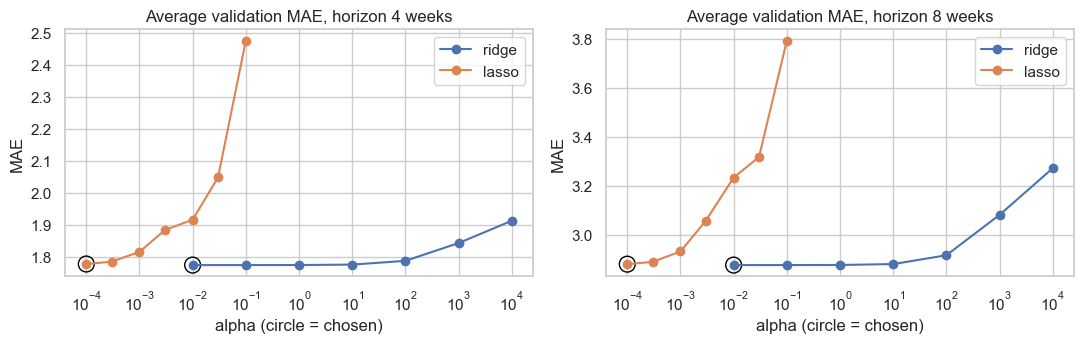

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, h in zip(axes, HORIZONS):
    for kind in ("ridge", "lasso"):
        d = avg_mae[(avg_mae["model"] == kind) & (avg_mae["horizon"] == h)]
        ax.plot(d["alpha"], d["mae"], marker="o", label=kind)
        b = d.loc[d["mae"].idxmin()]
        ax.scatter([b["alpha"]], [b["mae"]], s=130, facecolors="none", edgecolors="black")
    ax.set_xscale("log")
    ax.set_title(f"Average validation MAE, horizon {h} weeks")
    ax.set_xlabel("alpha (circle = chosen)")
    ax.set_ylabel("MAE")
    ax.legend()
plt.tight_layout()
plt.savefig(replace_existing(OUT_DIR / "figures" / "tuning_curves.png"), dpi=150)
plt.show()

In [61]:
# ---- validation predictions with the chosen settings (each fold is trained on its own past only)
lin_parts = []
for h in HORIZONS:
    S_h = SH[h]
    for kind in ("ridge", "lasso"):
        alpha = best_alpha[(kind, h)]
        pieces = []
        for fold in FOLDS:
            train = S_h[S_h["target_date"] <= fold["train_end"]]
            val = val_rows[h][fold["name"]]
            model = make_model(kind, alpha).fit(train[FEATURES], train["z_train"])
            pieces.append(pred_frame(val, predict_original_scale(model, val), kind, "validation"))
        lin_parts.extend(pieces)
print("Validation predictions done")

Validation predictions done


## 10. Test period: Ridge and Lasso retrained every 4 weeks

For the test period (January 2025 onward) a forecast is made for every week. The models are **retrained every 4 weeks** on all examples whose target was already observed at that point (this matches how the web application would be updated). The chosen `alpha` stays fixed. Every refit stores its coefficients (on standardised inputs, so they can be compared), which are saved for Person 2.

In [62]:
def walk_forward(kind, alpha, S_h, h):
    test = test_rows[h]
    p0 = pos[test["origin_date"].min()]
    block = (test["origin_date"].map(pos) - p0) // REFIT_EVERY
    preds, coefs = [], []
    for b, grp in test.groupby(block):
        refit_date = grp["origin_date"].min()
        train = S_h[S_h["target_date"] <= refit_date]       # only targets that are already known
        model = make_model(kind, alpha).fit(train[FEATURES], train["z_train"])
        preds.append(pd.Series(predict_original_scale(model, grp), index=grp.index))
        coef = model[-1].coef_
        coefs.append(pd.DataFrame({"model": kind, "horizon": h, "alpha": alpha,
                                   "refit_date": refit_date.strftime("%Y-%m-%d"),
                                   "n_train": len(train), "feature": FEATURES, "coefficient": coef}))
    return pd.concat(preds).reindex(test.index), pd.concat(coefs, ignore_index=True)


t0 = time.time()
coef_parts = []
for h in HORIZONS:
    for kind in ("ridge", "lasso"):
        p, c = walk_forward(kind, best_alpha[(kind, h)], SH[h], h)
        lin_parts.append(pred_frame(test_rows[h], p.to_numpy(), kind, "test"))
        coef_parts.append(c)
print(f"Walk-forward test finished in {time.time() - t0:.0f} s")

coefficients = pd.concat(coef_parts, ignore_index=True)
coefficients.to_csv(replace_existing(OUT_DIR / "coefficients.csv"), index=False)

coef_summary = (coefficients.groupby(["model", "horizon", "feature"])["coefficient"]
                .agg(mean_coef="mean", std_coef="std", share_nonzero=lambda s: (s != 0).mean(),
                     n_refits="count").reset_index())
coef_summary["abs_mean_coef"] = coef_summary["mean_coef"].abs()
coef_summary = coef_summary.sort_values(["model", "horizon", "abs_mean_coef"], ascending=[True, True, False])
coef_summary.to_csv(replace_existing(OUT_DIR / "coefficients_summary.csv"), index=False)

lasso_zero = (coef_summary[coef_summary.model == "lasso"].assign(zero=lambda d: d.share_nonzero == 0)
              .groupby("horizon")["zero"].sum())
print("Features that Lasso set to zero in every refit:", lasso_zero.to_dict())
coef_summary[(coef_summary.model == "lasso") & (coef_summary.horizon == HORIZONS[0])].head(10).round(3)

Walk-forward test finished in 58 s
Features that Lasso set to zero in every refit: {4: 0, 8: 0}


,model,horizon,feature,mean_coef,std_coef,share_nonzero,n_refits,abs_mean_coef
30,lasso,4,style_rel_mom_4,-0.112,0.054,1.0,24,0.112
16,lasso,4,lag_0,0.093,0.007,1.0,24,0.093
26,lasso,4,mom_4,0.071,0.056,1.0,24,0.071
24,lasso,4,market_mom_4,-0.056,0.010,1.0,24,0.056
29,lasso,4,style_rel,-0.054,0.014,1.0,24,0.054
27,lasso,4,mom_8,0.041,0.006,1.0,24,0.041
3,lasso,4,avg_8,-0.040,0.030,1.0,24,0.040
28,lasso,4,seas_lag,0.036,0.005,1.0,24,0.036
32,lasso,4,vol_8,0.031,0.021,1.0,24,0.031
23,lasso,4,market_index,-0.023,0.006,1.0,24,0.023


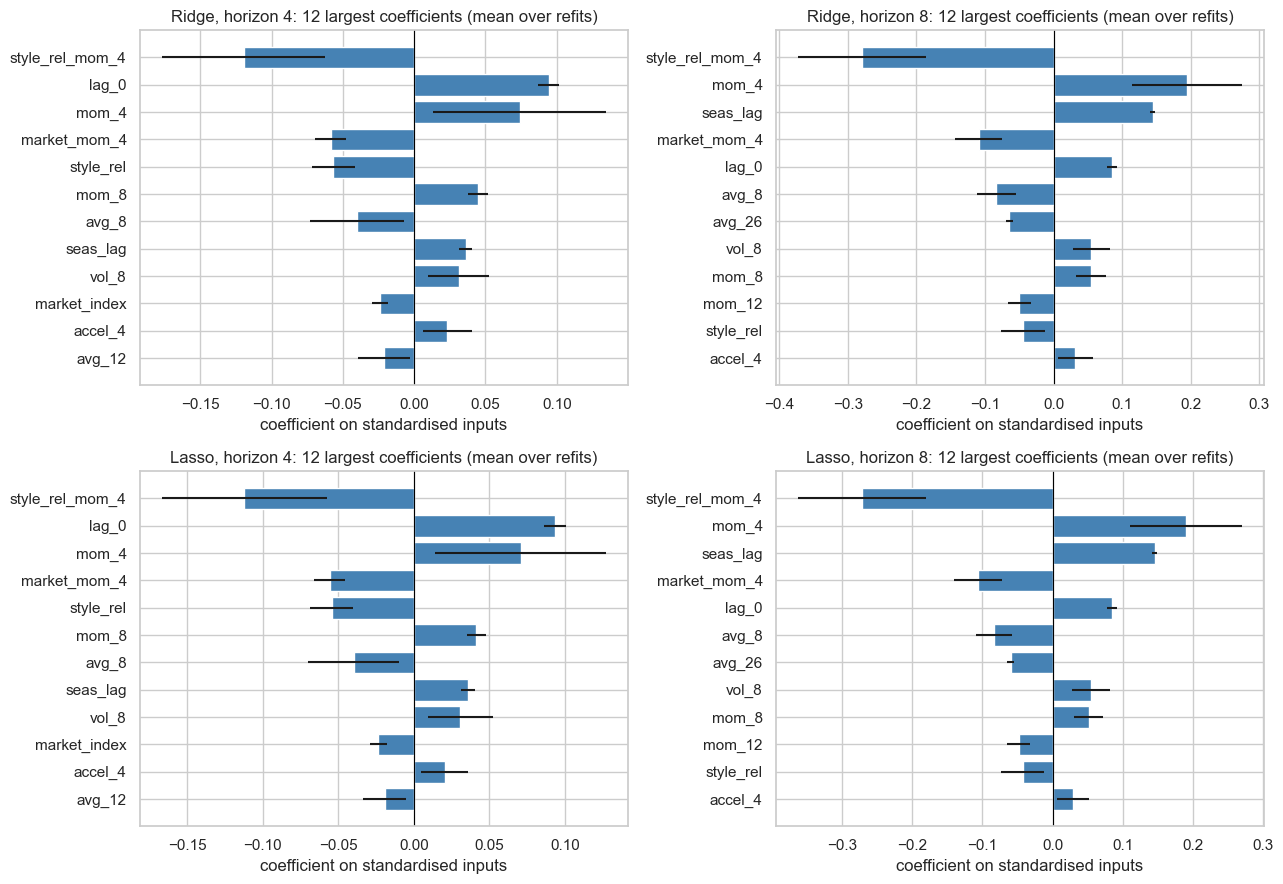

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, kind in enumerate(("ridge", "lasso")):
    for c, h in enumerate(HORIZONS):
        d = coef_summary[(coef_summary.model == kind) & (coef_summary.horizon == h)].head(12).iloc[::-1]
        axes[r, c].barh(d["feature"], d["mean_coef"], xerr=d["std_coef"].fillna(0), color="steelblue")
        axes[r, c].axvline(0, color="black", lw=0.8)
        axes[r, c].set_title(f"{kind.capitalize()}, horizon {h}: 12 largest coefficients (mean over refits)")
        axes[r, c].set_xlabel("coefficient on standardised inputs")
plt.tight_layout()
plt.savefig(replace_existing(OUT_DIR / "figures" / "ridge_lasso_coefficients.png"), dpi=150)
plt.show()

## 11. Save the predictions in the shared format

One CSV with the shared columns: `date` (the forecast-origin week), `item` (keyword), `horizon` (4 or 8), `actual`, `predicted`, `model`, `period` (validation or test), and `last4_avg`. `actual` and `predicted` are four-week averages ending `horizon` weeks after `date`. It contains the three baselines (`last_value`, `avg_4w`, `seasonal_naive`) and the three models (`ets`, `ridge`, `lasso`).

In [64]:
COLUMNS = ["date", "item", "horizon", "actual", "predicted", "model", "period", "last4_avg"]
predictions = pd.concat([baseline_preds, ets_preds] + lin_parts, ignore_index=True)[COLUMNS]
predictions = predictions.sort_values(["period", "horizon", "model", "item", "date"]).reset_index(drop=True)

# format checks
assert list(predictions.columns) == COLUMNS
assert predictions["horizon"].isin(HORIZONS).all() and predictions["period"].isin(["validation", "test"]).all()
assert predictions[["actual", "predicted", "last4_avg"]].notna().all().all(), "missing values in actual, predicted or last4_avg"
assert not predictions.duplicated(["date", "item", "horizon", "model", "period"]).any(), "duplicate rows"

predictions.to_csv(replace_existing(OUT_DIR / "predictions.csv"), index=False)
print(f"Saved predictions.csv: {len(predictions):,} rows")
predictions.groupby(["period", "horizon", "model"]).size().unstack("model")

Saved predictions.csv: 405,816 rows


model               avg_4w    ets  lasso  last_value  ridge  seasonal_naive
period     horizon                                                         
test       4         12729  12729  12729       12729  12729           12729
           8         12729  12729  12729       12729  12729           12729
validation 4         21105  21105  21105       21105  21105           21105
           8         21073  21073  21073       21073  21073           21073

## 12. Score table

Each model is scored on the **same rows** (rows where every model has a prediction), separately for each period and horizon.

| Score | Meaning |
|---|---|
| `mae` | mean absolute error on the original 0 to 100 scale (lower is better) |
| `rmse` | root mean squared error (penalises large errors more) |
| `mase` | MAE of the model divided by the MAE of the `avg_4w` / `last4_avg` baseline, computed per keyword and then averaged over keywords. Below 1 = better than that baseline |
| `direction_acc` | share of rows where the model predicts correctly whether interest goes up or down compared with the origin week (rows with no change are skipped; not defined for `last_value`) |

**Scopes** (the proposal asks to report the spring 2026 spike separately): `all` = every row; `2025_only` = test rows with target in 2025; `no_spike` = rows where neither the origin nor the target week is a flagged spike week. Because the inputs look back up to 26 weeks (and the market index uses a trailing year), a spike also affects forecasts made for a while **after** it. `no_spike_window` is therefore stricter: it also removes every row whose 26-week look-back, origin or target touches a spike week.

In [65]:
MODEL_ORDER = ["last_value", "avg_4w", "seasonal_naive", "ets", "ridge", "lasso"]


def compute_scores(pred, item_filter=None):
    p = pred.copy()
    p["date"] = pd.to_datetime(p["date"])
    if item_filter is not None:
        p = p[p["item"].isin(item_filter)]
    keys = ["period", "horizon", "date", "item"]
    wide = p.pivot_table(index=keys, columns="model", values="predicted", aggfunc="first").dropna()
    models = [m for m in MODEL_ORDER if m in wide.columns]
    row_info = p.drop_duplicates(keys).set_index(keys)
    act = row_info["actual"].reindex(wide.index)
    last4 = row_info["last4_avg"].reindex(wide.index)
    info = wide.index.to_frame(index=False)
    origin = info["date"] - pd.to_timedelta(info["horizon"] * 7, unit="D")
    is_spike = (info["date"].map(spike_map).fillna(False).astype(bool)
                | origin.map(spike_map).fillna(False).astype(bool)).to_numpy()
    in_2025 = ((info["period"] == "test") & (info["date"].dt.year == 2025)).to_numpy()
    spike_cum = np.concatenate([[0], spike_flag.astype(int).cumsum().to_numpy()])   # spike weeks among the first i weeks
    t_pos = info["date"].map(pos).to_numpy()
    o_pos = origin.map(pos).to_numpy()
    start = np.maximum(o_pos - 26, 0)                                               # 26-week look-back of the inputs
    clean_window = (spike_cum[t_pos + 1] - spike_cum[start]) == 0                   # no spike week in look-back, origin or target
    scopes = {"all": np.ones(len(info), bool), "2025_only": in_2025, "no_spike": ~is_spike,
              "no_spike_window": clean_window}

    out = []
    for (period, h), idx in info.groupby(["period", "horizon"]).groups.items():
        idx = np.asarray(idx)
        for scope, mask in scopes.items():
            sel = idx[mask[idx]]
            if len(sel) == 0:
                continue
            a = act.to_numpy()[sel]
            y0 = last4.to_numpy()[sel]                                      # 4-week average at the forecast origin
            items = info["item"].to_numpy()[sel]
            baseline_err = pd.Series(np.abs(a - y0)).groupby(items).mean().replace(0, np.nan)
            for m in models:
                pr = wide[m].to_numpy()[sel]
                err = a - pr
                item_mae = pd.Series(np.abs(err)).groupby(items).mean()
                if m == "last_value":
                    dacc = np.nan
                else:
                    ok = (a != y0) & (pr != y0)
                    dacc = float((np.sign(pr - y0)[ok] == np.sign(a - y0)[ok]).mean()) if ok.any() else np.nan
                out.append(dict(model=m, period=period, horizon=h, scope=scope, n_rows=len(sel),
                                n_items=len(baseline_err.index), mae=float(np.mean(np.abs(err))),
                                rmse=float(np.sqrt(np.mean(err ** 2))),
                                mase=float((item_mae / baseline_err).mean()), direction_acc=dacc))
    res = pd.DataFrame(out)
    res["model"] = pd.Categorical(res["model"], MODEL_ORDER, ordered=True)
    return res.sort_values(["period", "horizon", "scope", "model"]).reset_index(drop=True)


scores = compute_scores(predictions)
scores_out = scores.copy()
scores_out["model"] = scores_out["model"].astype(str)
scores_out.round(4).to_csv(replace_existing(OUT_DIR / "scores.csv"), index=False)

# scores by category (test period, all weeks)
cat_rows = []
for cat in category_levels:
    items = [k for k in Y.columns if category[k] == cat]
    s = compute_scores(predictions[predictions["period"] == "test"], items)
    s = s[s["scope"] == "all"].assign(category=cat)
    cat_rows.append(s)
scores_by_category = pd.concat(cat_rows, ignore_index=True)
scores_by_category["model"] = scores_by_category["model"].astype(str)
scores_by_category.round(4).to_csv(replace_existing(OUT_DIR / "scores_by_category.csv"), index=False)

print("Test period, all weeks:")
scores[(scores["period"] == "test") & (scores["scope"] == "all")].drop(columns=["period", "scope"]).round(3)

Test period, all weeks:


,model,horizon,n_rows,n_items,mae,rmse,mase,direction_acc
6,last_value,4,12729,137,5.928,10.934,0.832,NaN
7,avg_4w,4,12729,137,7.237,12.364,1.000,NaN
8,seasonal_naive,4,12729,137,11.305,18.696,1.667,0.628
9,ets,4,12729,137,6.399,12.544,0.893,0.702
10,ridge,4,12729,137,7.760,14.709,1.103,0.682
11,lasso,4,12729,137,7.723,14.553,1.097,0.681
30,last_value,8,12729,137,10.367,17.225,0.965,NaN
31,avg_4w,8,12729,137,10.895,17.675,1.000,NaN
32,seasonal_naive,8,12729,137,11.305,18.696,1.131,0.645
33,ets,8,12729,137,10.951,19.877,1.011,0.615


In [66]:
print("Test period, without spike weeks:")
display_cols = ["model", "horizon", "n_rows", "mae", "rmse", "mase", "direction_acc"]
scores[(scores["period"] == "test") & (scores["scope"] == "no_spike")][display_cols].round(3)

Test period, without spike weeks:


,model,horizon,n_rows,mae,rmse,mase,direction_acc
12,last_value,4,10537,4.266,7.745,0.826,NaN
13,avg_4w,4,10537,5.238,9.349,1.000,NaN
14,seasonal_naive,4,10537,7.593,12.437,1.576,0.627
15,ets,4,10537,4.336,7.978,0.845,0.706
16,ridge,4,10537,4.525,9.090,0.899,0.731
17,lasso,4,10537,4.508,8.980,0.896,0.730
36,last_value,8,10263,8.120,14.225,0.992,NaN
37,avg_4w,8,10263,8.252,14.079,1.000,NaN
38,seasonal_naive,8,10263,9.957,17.304,1.315,0.621
39,ets,8,10263,8.155,14.486,0.995,0.602


In [67]:
print("Validation (three yearly folds together), all weeks:")
scores[(scores["period"] == "validation") & (scores["scope"] == "all")][display_cols].round(3)

Validation (three yearly folds together), all weeks:


,model,horizon,n_rows,mae,rmse,mase,direction_acc
48,last_value,4,21105,1.972,3.687,0.891,NaN
49,avg_4w,4,21105,2.398,4.350,1.000,NaN
50,seasonal_naive,4,21105,4.668,8.550,2.176,0.655
51,ets,4,21105,1.995,4.005,0.905,0.700
52,ridge,4,21105,1.773,3.641,0.824,0.742
53,lasso,4,21105,1.777,3.635,0.825,0.740
66,last_value,8,21073,3.626,6.442,0.954,NaN
67,avg_4w,8,21073,3.960,6.903,1.000,NaN
68,seasonal_naive,8,21073,4.665,8.539,1.405,0.701
69,ets,8,21073,3.530,6.694,0.946,0.651


## 13. Graphs

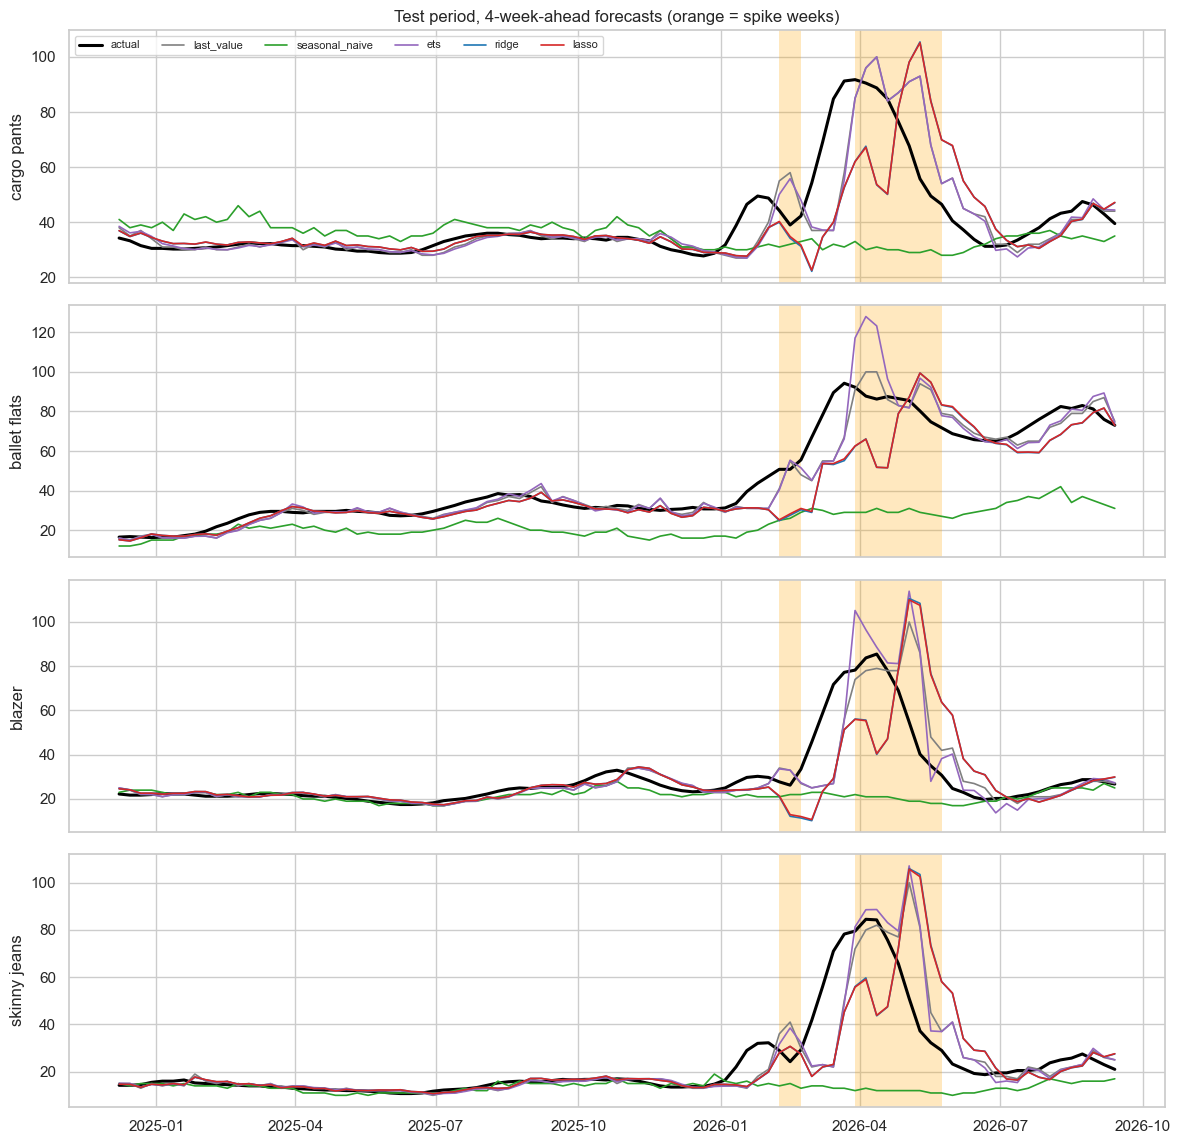

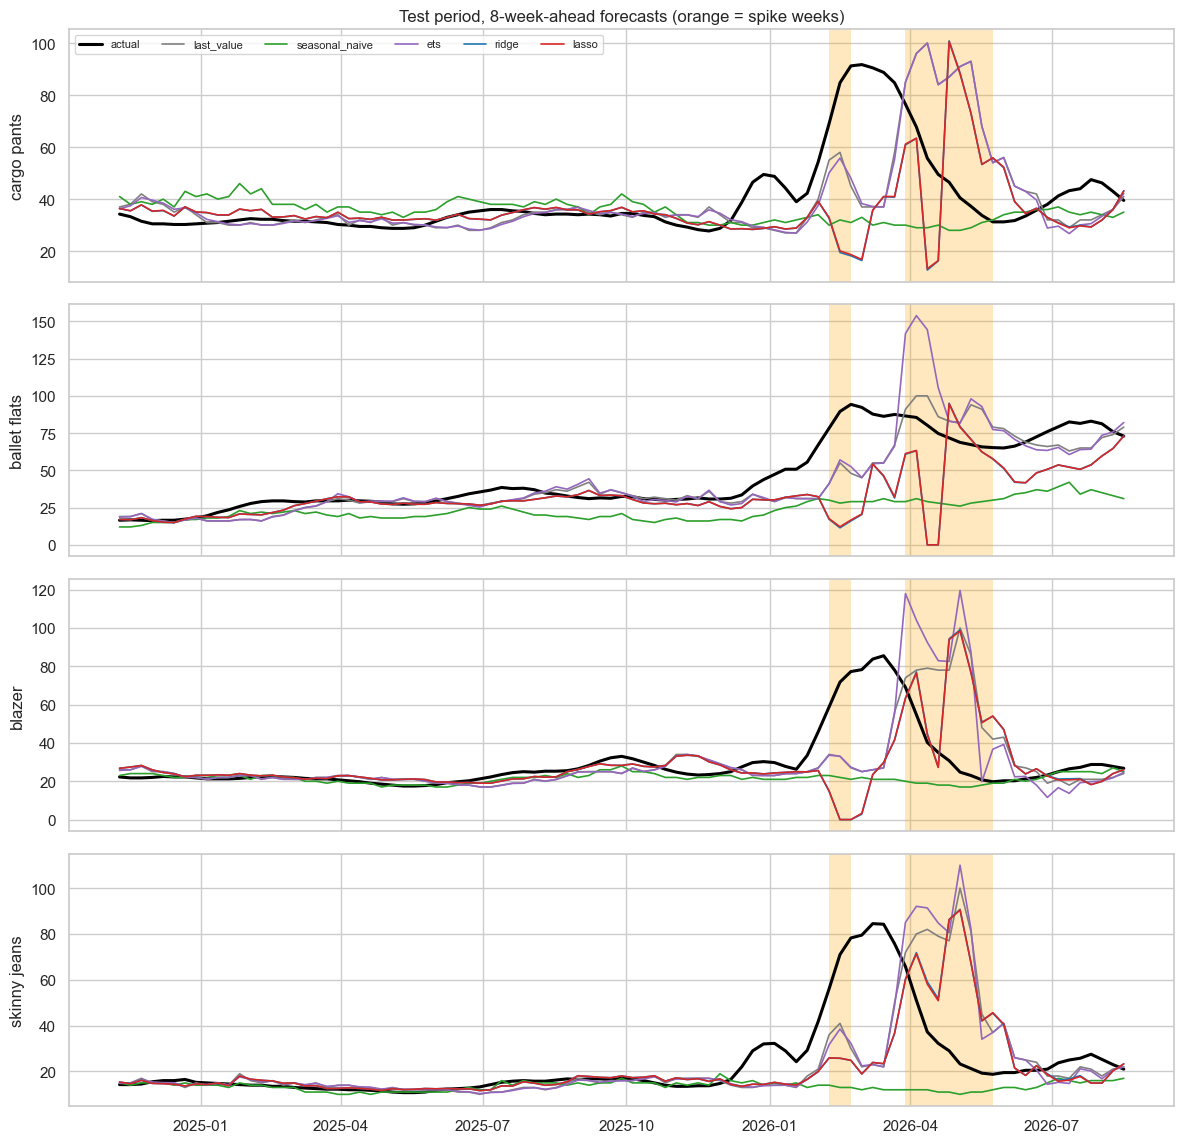

In [68]:
EXAMPLES = [k for k in ["cargo pants", "ballet flats", "blazer", "skinny jeans"] if k in Y.columns] or list(Y.columns[:4])
LINES = [("last_value", "grey"), ("seasonal_naive", "tab:green"), ("ets", "tab:purple"),
         ("ridge", "tab:blue"), ("lasso", "tab:red")]

for h in HORIZONS:
    fig, axes = plt.subplots(len(EXAMPLES), 1, figsize=(12, 2.9 * len(EXAMPLES)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, kw in zip(axes, EXAMPLES):
        d = predictions[(predictions["item"] == kw) & (predictions["horizon"] == h) & (predictions["period"] == "test")].copy()
        d["date"] = pd.to_datetime(d["date"])
        wide = d.pivot_table(index="date", columns="model", values="predicted", aggfunc="first")
        actual = d.drop_duplicates("date").set_index("date")["actual"]
        for wk in actual.index[[bool(spike_map.get(x, False)) for x in actual.index]]:
            ax.axvspan(wk, wk + pd.Timedelta(days=7), color="orange", alpha=0.25, lw=0)
        ax.plot(actual.index, actual, color="black", lw=2.2, label="actual")
        for m, col in LINES:
            if m in wide:
                ax.plot(wide.index, wide[m], color=col, lw=1.2, label=m)
        ax.set_ylabel(kw)
    axes[0].set_title(f"Test period, {h}-week-ahead forecasts (orange = spike weeks)")
    axes[0].legend(ncol=6, fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.savefig(replace_existing(OUT_DIR / "figures" / f"forecast_examples_h{h}.png"), dpi=150)
    plt.show()

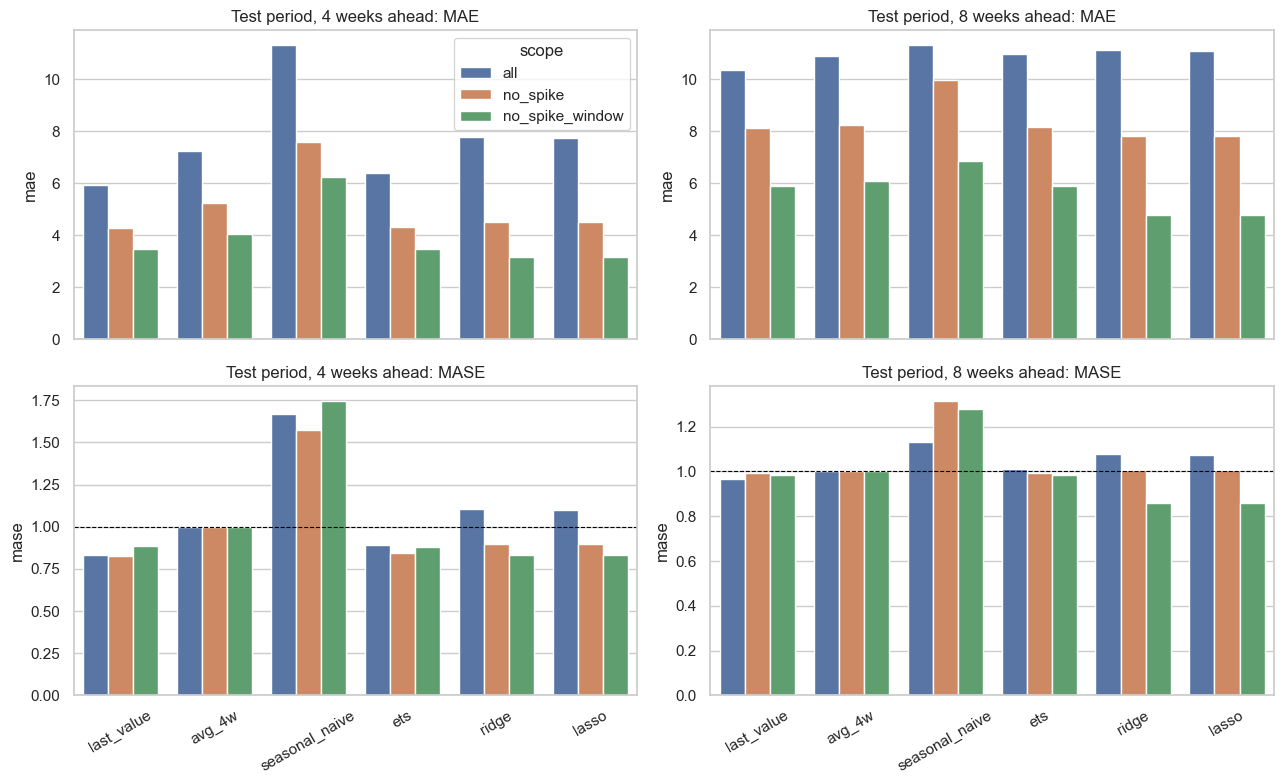

In [69]:
sc = scores[(scores["period"] == "test") & (scores["scope"].isin(["all", "no_spike", "no_spike_window"]))].copy()
sc["model"] = sc["model"].astype(str)
fig, axes = plt.subplots(2, len(HORIZONS), figsize=(6.5 * len(HORIZONS), 8), sharex=True)
for r, metric in enumerate(["mae", "mase"]):
    for c, h in enumerate(HORIZONS):
        ax = axes[r, c]
        sns.barplot(data=sc[sc["horizon"] == h], x="model", y=metric, hue="scope", order=MODEL_ORDER, ax=ax)
        ax.set_title(f"Test period, {h} weeks ahead: {metric.upper()}")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
        if metric == "mase":
            ax.axhline(1, color="black", lw=0.8, linestyle="--")
        if not (r == 0 and c == 0):
            ax.get_legend().remove()
plt.tight_layout()
plt.savefig(replace_existing(OUT_DIR / "figures" / "score_comparison.png"), dpi=150)
plt.show()

## 14. Summary for the short write-up

The results below are the final summary for the report. The prediction target is the four-week average ending `horizon` weeks after the forecast-origin date.

## Writeup
**What I did.** Finished the cleaning of the Google Trends data (weak-stitch keywords use the recent window only, emerging styles are kept and flagged, spike weeks are flagged and not deleted), built the inputs (previous weeks, recent averages, growth, volatility, seasonality, market index, category), split the data by time (three yearly validation folds 2022 to 2024 and a test period from January 2025), ran three baselines (latest value, 4-week average, same week last year) and trained ETS, Ridge and Lasso. Ridge and Lasso were tuned on the validation folds and retrained every 4 weeks in the test period.

**What I found.** On the full test period, `last_value` is the strongest baseline at both horizons: MAE 5.93 at 4 weeks and 10.37 at 8 weeks. ETS is the best of the fitted simpler models, but it does not beat that baseline: its MAE is 6.40 at 4 weeks (-8.0% relative to `last_value`) and 10.95 at 8 weeks (-5.6%). The ETS MASE is 0.89 at 4 weeks and 1.01 at 8 weeks when MASE is normalized by the shared 4-week-average baseline; therefore, ETS beats the 4-week-average baseline at 4 weeks but not the strongest `last_value` baseline.

The spike sensitivity analysis gives the same conclusion. Without flagged spike weeks, ETS has MAE 4.34 versus 4.27 for the best baseline at 4 weeks, and 8.15 versus 8.12 at 8 weeks. Excluding spike weeks and their look-back windows reduces errors to 3.46 versus 3.47 at 4 weeks and 5.91 versus 5.89 at 8 weeks, but the differences are negligible. The model advantage is therefore not robust enough to claim that ETS improves on the simple baseline.

Validation selected Lasso `alpha=0.0001` and Ridge `alpha=0.01` for both horizons. The five largest horizon-4 Ridge features were `style_rel_mom_4`, `lag_0`, `mom_4`, `market_mom_4` and `style_rel`. The run used 137 keywords, flagged 3 as emerging, identified 6 weak stitches and flagged 10 spike weeks. These coefficients are predictive associations, not causal effects.

**What changed from the proposal, and why.**

| Change | Why |
|---|---|
| The current week (`lag_0`) is also an input | Inputs may use the forecast week itself; it is the most recent information |
| Keywords are dropped for low volume using the **last 104 weeks** instead of all weeks | The old rule removed emerging styles (`balletcore`, `clean girl aesthetic`, `gorpcore`) that we want to forecast; they are now kept with an `emerging` flag |
| Spike weeks are flagged with a threshold of **0.25** (EDA used 0.5) | At 0.5 only 4 weeks were flagged and most of the spike remained |
| ETS has no seasonal part (damped additive trend only) | Keeps ETS fast and simple; the seasonal naive baseline shows what seasonality alone gives |
| Rows need a 4-week average of at least 1 and 52 weeks of valid history | Ratios of tiny numbers are unstable; all models are scored on the same rows |
| Training target is clipped at 5 times the recent level | A few extreme ratios would otherwise dominate the fit; errors are still measured on the real 0 to 100 scale |
| Validation: models trained once per fold (ETS: one fit per fold, state updated weekly) | Validation is only used to choose `alpha`; the 4-weekly refits are used for the test period |
| MASE is computed per keyword against the `avg_4w` / `last4_avg` baseline and then averaged | Matches the shared comparison metric; allows averaging across keywords with different scales |

## 15. Output checklist

Everything below goes to GitHub in `results/google_trends/`.

In [71]:
readme = """# results/google_trends (Person 1)

Shared format agreed with the team. All dates are week start dates (Sundays).

| File | Content |
|---|---|
| predictions.csv | date (week predicted), item (keyword), horizon (4 or 8), actual, predicted, model, period (validation/test). Models: last_value, avg_4w, seasonal_naive, ets, ridge, lasso |
| scores.csv | model, period, horizon, scope (all / 2025_only / no_spike / no_spike_window), n_rows, n_items, mae, rmse, mase, direction_acc |
| scores_by_category.csv | same scores for the test period by keyword category |
| prepared_dataset.csv.gz | shared prepared dataset (eligible rows). One row per origin week, keyword and horizon, with inputs, target and period label |
| feature_list.json | list of input columns, and how the target and predictions are scaled |
| splits.json | validation folds, test start and refit schedule |
| coefficients.csv / coefficients_summary.csv | Ridge and Lasso coefficients (standardised inputs) for every 4-weekly refit, and their mean over refits |
| tuning_results.csv | validation MAE for every alpha and fold; chosen = True marks the selected alpha |
| keyword_info.csv, spike_weeks.csv, trends_weekly_prepared.csv | cleaning flags per keyword, flagged spike weeks, cleaned weekly table |
| figures/ | forecast examples, score comparison, tuning curves, coefficients |

Scaling used by the models: every input and the target are divided by the 4-week average at the origin week (base);
predicted = max(model output, 0) * base.
"""
replace_existing(OUT_DIR / "README.md").write_text(readme)

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file())
pd.DataFrame({"file": [str(p.relative_to(OUT_DIR)) for p in files],
              "size_kb": [round(p.stat().st_size / 1024, 1) for p in files]})

,file,size_kb
0,README.md,1.5
1,coefficients.csv,213.1
2,coefficients_summary.csv,13.0
3,feature_importance_shap.csv,1.7
4,feature_list.json,1.5
5,figures/feature_importance_shap.png,69.9
6,figures/forecast_examples_h4.png,386.3
7,figures/forecast_examples_h8.png,389.2
8,figures/forecasts_h4.png,237.7
9,figures/forecasts_h8.png,236.6
